# 01 · Keluarga Autoencoder: Vanilla AE, Sparse AE, VAE
**Deep Learning (D6421) – Sesi 07: Generative Models | Tugas Take-Home**

Melatih ketiga autoencoder dengan backbone yang sama (`784→256→64→256→784`), menghitung MSE/PSNR/SSIM, sparsity laten, FID & coverage untuk VAE, sweep λ Sparse AE, serta Figur 1 dan Figur Pendukung S1/S3. Bahan untuk Q1, Q2, Q4, Q6.

**Sebelum run (Colab):** *Runtime → Change runtime type → T4 GPU*. Notebook akan meminta izin mount Google Drive; semua checkpoint, tabel, dan figur disimpan ke folder `GSLC2/final_results/` di Drive.

Notebook ini **mandiri**: model yang dibutuhkan tapi belum ada di Drive akan dilatih di sini. Kalau sudah dilatih notebook lain (folder output yang sama), checkpoint-nya langsung dimuat.

## 1. Setup

In [1]:
!pip install -q torch-fidelity torchmetrics

In [2]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import copy
import csv
import glob
import json
import math
import random
import shutil
import statistics
import time
from dataclasses import asdict, dataclass
from typing import Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, Markdown, display
from matplotlib.gridspec import GridSpec
from torch.utils.data import DataLoader, TensorDataset

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.14.1+cu130 | CUDA: True | Tesla T4


### Konfigurasi
Semua hyperparameter ada di sini, jadi bisa langsung dipindah ke **Tabel Konfigurasi** (Bagian II laporan). Nilainya identik di kelima notebook.

In [3]:
@dataclass
class Config:
    # ---- Umum ----
    seed: int = 42
    data_root: str = "./data"
    out_dir: str = "./outputs"
    batch_size: int = 128
    num_workers: int = 0              # data di-preload ke tensor -> 0 sudah cepat
    fake_data: bool = False           # True = smoke test dengan data sintetis
    deterministic: bool = False
    train_frac: float = 0.8
    val_frac: float = 0.1

    # ---- Keluarga Autoencoder (backbone sama: 784-256-64-256-784) ----
    img_dim: int = 784
    hidden_dim: int = 256
    latent_dim: int = 64
    ae_epochs: int = 30
    ae_lr: float = 1e-3
    sparse_lambda: float = 1e-4       # lambda * ||h||_1
    sparse_sweep: Tuple[float, ...] = (0.0, 1e-5, 1e-4, 1e-3)
    sweep_epochs: int = 20
    vae_recon_loss: str = "bce"       # "bce" | "mse" (dijumlah per citra)
    vae_beta: float = 1.0

    # ---- GAN ----
    z_dim: int = 100
    gan_epochs: int = 60
    dcgan_epochs: int = 30
    gan_lr: float = 2e-4
    gan_beta1: float = 0.5
    gan_loss: str = "nonsat"          # "nonsat" | "minimax"
    dcgan_ngf: int = 64
    dcgan_ndf: int = 64
    gan_log_every: int = 10

    # ---- DDPM ----
    ddpm_epochs: int = 40
    ddpm_lr: float = 2e-4
    ddpm_T: int = 1000
    ddpm_beta_start: float = 1e-4
    ddpm_beta_end: float = 0.02
    ddpm_base_ch: int = 64
    ddpm_ch_mults: Tuple[int, ...] = (1, 2, 2)
    ddpm_num_res_blocks: int = 2
    ddpm_attn_res: Tuple[int, ...] = (7,)
    ddpm_dropout: float = 0.1
    ddpm_ema_decay: float = 0.999
    ddpm_amp: bool = True
    ddpm_sample_batch: int = 500
    ddpm_val_batches: int = 20

    # ---- MLP Classifier (Bagian 2): 784 -> 256 -> 64 -> 10 ----
    clf_epochs: int = 25
    clf_lr: float = 1e-3
    clf_dropout: float = 0.2
    clf_min_acc: float = 0.88
    latent_dec_epochs: int = 30       # = ae_epochs agar adil vs Vanilla AE

    # ---- Evaluasi ----
    fid_feature: int = 2048
    fid_n_samples: int = 0            # 0 = samakan dengan ukuran test set
    fid_batch: int = 100              # Inception resize ke 299x299 -> batch besar = OOM di T4
    latency_batch: int = 64
    latency_runs: int = 20
    latency_runs_ddpm: int = 3
    interp_classes: Tuple[int, int] = (1, 8)      # Trouser vs Bag
    interp_alphas: Tuple[float, ...] = (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)
    gan_interp_candidates: int = 2000

    def apply_fake_data_overrides(self):
        """Mode smoke test: semuanya kecil agar pipeline bisa dicek cepat di CPU."""
        self.ae_epochs = self.sweep_epochs = self.clf_epochs = self.latent_dec_epochs = 1
        self.gan_epochs = self.dcgan_epochs = self.ddpm_epochs = 1
        self.ddpm_T = 20
        self.ddpm_base_ch = 32
        self.ddpm_num_res_blocks = 1
        self.ddpm_sample_batch = 64
        self.ddpm_val_batches = 2
        self.fid_n_samples = 128
        self.latency_runs = 2
        self.latency_runs_ddpm = 1
        self.sparse_sweep = (0.0, 1e-4)
        self.clf_min_acc = 0.0
        self.gan_interp_candidates = 200


CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


GENERATIVE = ["vanilla_ae", "sparse_ae", "vae", "vanilla_gan", "dcgan", "ddpm"]


PRETTY = {"vanilla_ae": "Vanilla AE", "sparse_ae": "Sparse AE", "vae": "VAE",
          "vanilla_gan": "Vanilla GAN", "dcgan": "DCGAN", "ddpm": "DDPM",
          "mlp_classifier": "MLP Classifier", "latent_decoder": "Frozen-Latent Decoder"}

### Utilitas

In [4]:
def set_seed(seed=42, deterministic=False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path


def _json_default(o):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, torch.Tensor):
        return o.detach().cpu().tolist()
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"Tidak bisa serialisasi {type(o)}")


def save_json(obj, path):
    ensure_dir(os.path.dirname(path) or ".")
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=_json_default)


def to_01(x):
    """[-1, 1] -> [0, 1]"""
    return ((x + 1) / 2).clamp(0, 1)


def to_pm1(x):
    """[0, 1] -> [-1, 1]"""
    return x * 2 - 1


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def _sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def measure_latency(fn, device, n_warmup=3, n_runs=20):
    """Median & std latensi (ms) satu pemanggilan fn(). synchronize agar waktu GPU terhitung."""
    for _ in range(n_warmup):
        fn()
    _sync(device)
    times = []
    for _ in range(n_runs):
        _sync(device)
        t0 = time.perf_counter()
        fn()
        _sync(device)
        times.append((time.perf_counter() - t0) * 1000.0)
    return {"median_ms": statistics.median(times),
            "std_ms": statistics.pstdev(times) if len(times) > 1 else 0.0,
            "n_runs": n_runs}


def _free_cuda():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

### Data
torchvision memberi split 60k/10k; keduanya digabung (70k) lalu dipecah ulang **80/10/10** dengan seed 42. Karena seed-nya sama, kelima notebook mendapat split yang identik.

In [5]:
def _load_fashion_mnist(root):
    from torchvision.datasets import FashionMNIST
    tr = FashionMNIST(root, train=True, download=True)
    te = FashionMNIST(root, train=False, download=True)
    # Gabung split resmi 60k + 10k = 70k, lalu split ulang 80/10/10.
    x = torch.cat([tr.data, te.data], 0).float().div_(255.0).unsqueeze(1)  # (70000,1,28,28) in [0,1]
    y = torch.cat([tr.targets, te.targets], 0).long()
    return x, y


def _make_fake_data(n=3000, seed=0):
    """Data sintetis (blob) HANYA untuk smoke test pipeline, bukan untuk laporan."""
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, 10, (n,), generator=g)
    yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")
    cx = 6 + 1.6 * y.float() + torch.randn(n, generator=g)
    cy = 14 + 3 * torch.randn(n, generator=g)
    r = 4 + 0.3 * y.float()
    d = ((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2).sqrt()
    return torch.sigmoid((r[:, None, None] - d) * 1.5).unsqueeze(1).clamp(0, 1), y


def get_data(cfg):
    x, y = _make_fake_data(seed=cfg.seed) if cfg.fake_data else _load_fashion_mnist(cfg.data_root)
    n = len(x)
    n_train, n_val = int(cfg.train_frac * n), int(cfg.val_frac * n)
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(cfg.seed))
    idx = {"train": perm[:n_train], "val": perm[n_train:n_train + n_val], "test": perm[n_train + n_val:]}
    torch.save(idx, os.path.join(cfg.out_dir, "logs", "split_indices.pt"))
    save_json({"n_total": n, **{f"n_{k}": len(v) for k, v in idx.items()}, "seed": cfg.seed},
              os.path.join(cfg.out_dir, "logs", "split_info.json"))
    ds = {k: TensorDataset(x[v], y[v]) for k, v in idx.items()}

    pin = torch.cuda.is_available()
    loaders = {
        "train": DataLoader(ds["train"], batch_size=cfg.batch_size, shuffle=True, drop_last=True,
                            num_workers=cfg.num_workers, pin_memory=pin,
                            generator=torch.Generator().manual_seed(cfg.seed)),
        "val": DataLoader(ds["val"], batch_size=cfg.batch_size, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=pin),
        "test": DataLoader(ds["test"], batch_size=cfg.batch_size, shuffle=False,
                           num_workers=cfg.num_workers, pin_memory=pin),
    }
    log(f"Data: total={n} | train={len(idx['train'])} val={len(idx['val'])} test={len(idx['test'])}")
    return ds, loaders

## 2. Pengaturan Run
- Run penuh untuk laporan. Semua hasil tersimpan langsung ke Drive: `GSLC2/final_results/`.
- Semua notebook Colab berbagi folder ini, jadi model yang sudah dilatih notebook lain langsung dimuat.

In [6]:
# ======================= PENGATURAN RUN =======================
FAKE_DATA = False     # smoke test dengan data sintetis (JANGAN untuk laporan)
SKIP_FID = False
RETRAIN = ["vanilla_ae", "sparse_ae", "vae"]          # mis. ["dcgan"] untuk paksa latih ulang walau checkpoint sudah ada di Drive

# Folder Google Drive (My Drive > Binus > Semester_5 > DeepLearning > GSLC2)
DRIVE_DIR = "/content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = DRIVE_DIR
    DATA_ROOT = "/content/data"           # dataset di disk lokal Colab (lebih cepat dari Drive)
except ImportError:                       # dijalankan di luar Colab
    BASE = "./GSLC2"
    DATA_ROOT = "./data"

cfg = Config(data_root=DATA_ROOT,
             out_dir=os.path.join(BASE, "final_results"))
if FAKE_DATA:
    cfg.fake_data = True
    cfg.apply_fake_data_overrides()

for d in ["checkpoints", "logs", "figures", "metrics", "samples"]:
    ensure_dir(os.path.join(cfg.out_dir, d))

# Tes tulis ke Drive: gagal di sini = Drive penuh / path salah -> berhenti sebelum training
_probe = os.path.join(cfg.out_dir, ".write_test")
try:
    with open(_probe, "wb") as f:
        f.write(os.urandom(1024 * 1024))
    os.remove(_probe)
except OSError as e:
    raise RuntimeError(f"Tidak bisa menulis ke {cfg.out_dir}. Cek storage Google Drive / path DRIVE_DIR. ({e})")

device = get_device()
set_seed(cfg.seed, cfg.deterministic)
print("Output dir:", os.path.abspath(cfg.out_dir))
print("Device    :", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Mounted at /content/drive
Output dir: /content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2/final_results
Device    : cuda Tesla T4


In [7]:
ds, loaders = get_data(cfg)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.6MB/s]


[15:28:35] Data: total=70000 | train=56000 val=7000 test=7000


In [8]:
def ckpt_path(name):
    return os.path.join(cfg.out_dir, "checkpoints", f"{name}.pt")


def load_or_train(name, train_fn):
    """Load checkpoint dari Drive kalau ada (dan tidak di RETRAIN); kalau tidak, latih lalu simpan."""
    path = ckpt_path(name)
    if os.path.exists(path) and name not in RETRAIN:
        ck = torch.load(path, map_location=device, weights_only=False)
        mods = build_models(name, cfg, device)
        for k, sd in ck["state"].items():
            mods[k].load_state_dict(sd)
        hist = ck["hist"]
        log(f"Checkpoint dimuat dari Drive: {name}")
    else:
        log(f"=== Training {PRETTY.get(name, name)} ===")
        # Reset urutan shuffle -> hasil tiap model tidak bergantung pada model lain yang dilatih sebelumnya
        loaders["train"].generator.manual_seed(cfg.seed)
        mods, hist = train_fn()
        torch.save({"state": {k: v.state_dict() for k, v in mods.items()}, "hist": hist,
                    "config": asdict(cfg)}, path)
        save_json(hist, os.path.join(cfg.out_dir, "logs", f"{name}_history.json"))
    for v in mods.values():
        v.eval()
    return mods, hist


def show_fig(name, width=1100):
    display(Image(filename=os.path.join(cfg.out_dir, "figures", name), width=width))

## 3. Model
- Vanilla AE: $\mathcal{L}=\frac{1}{N}\|x-\hat x\|^2$
- Sparse AE: $\mathcal{L}=\text{MSE}+\lambda\,\mathbb{E}\|h\|_1$ (laten ReLU)
- VAE: $-\text{ELBO}=\mathbb{E}_q[-\log p(x|z)]+\beta\,\mathrm{KL}(q(z|x)\|\mathcal{N}(0,I))$

MLP Classifier ikut didefinisikan karena dipakai untuk mengukur *class coverage* sampel VAE.

In [9]:
class VanillaAE(nn.Module):
    """z = f(x) (linear, padat), x_hat = g(z). Backbone identik dgn ekstraktor fitur MLP Classifier."""

    def __init__(self, img_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(img_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, latent_dim))
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, img_dim), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

    @torch.no_grad()
    def reconstruct(self, x):
        return self.forward(x)[0]


class SparseAE(VanillaAE):
    """Arsitektur sama; kode laten ReLU + penalti L1. ReLU memungkinkan unit benar-benar nol."""

    def __init__(self, img_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__(img_dim, hidden_dim, latent_dim)
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(img_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, latent_dim), nn.ReLU(inplace=True))


class VAE(nn.Module):
    """q(z|x) = N(mu, diag(sigma^2)), p(z) = N(0, I)."""

    def __init__(self, img_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.enc_body = nn.Sequential(nn.Flatten(), nn.Linear(img_dim, hidden_dim), nn.ReLU(inplace=True))
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, img_dim), nn.Sigmoid())

    def encode(self, x):
        h = self.enc_body(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparameterization trick
        return self.decode(z), mu, logvar, z

    @torch.no_grad()
    def reconstruct(self, x):
        return self.decode(self.encode(x)[0])          # pakai mean posterior

    @torch.no_grad()
    def sample(self, n, device, generator=None):
        return self.decode(torch.randn(n, self.latent_dim, device=device, generator=generator))


def ae_loss(recon, x):
    """L_AE = mean ||x - x_hat||^2 (per piksel)."""
    return F.mse_loss(recon, x)


def sparse_ae_loss(recon, x, z, lam):
    """L_SAE = MSE + lambda * E_batch[||h||_1]."""
    rec = F.mse_loss(recon, x)
    l1 = z.abs().sum(1).mean()
    return rec + lam * l1, rec, l1


def vae_loss(recon, x, mu, logvar, recon_type="bce", beta=1.0):
    """-ELBO per citra = E_q[-log p(x|z)] + beta * KL(q(z|x) || N(0,I))."""
    b = x.size(0)
    if recon_type == "bce":
        rec = F.binary_cross_entropy(recon, x, reduction="sum") / b
    else:
        rec = F.mse_loss(recon, x, reduction="sum") / b
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / b
    return rec + beta * kl, rec, kl

In [10]:
class MLPClassifier(nn.Module):
    """784 -> 256 -> 64 -> 10. Bobot PyTorch berbentuk (out, in):
    W1=(256,784), W2=(64,256), W3=(10,64). z_MLP = ReLU(W2 ReLU(W1 x + b1) + b2) in R^64."""

    def __init__(self, img_dim=784, h1=256, h2=64, n_classes=10, dropout=0.2):
        super().__init__()
        self.fc1, self.fc2, self.fc3 = nn.Linear(img_dim, h1), nn.Linear(h1, h2), nn.Linear(h2, n_classes)
        self.drop = nn.Dropout(dropout)

    def features(self, x):
        return torch.relu(self.fc2(self.drop(torch.relu(self.fc1(x.flatten(1))))))

    def forward(self, x):
        return self.fc3(self.drop(self.features(x)))

    def weights(self):
        return self.fc1.weight.detach(), self.fc2.weight.detach(), self.fc3.weight.detach()


def train_classifier(cfg, loaders, device):
    """Tahap 1: MLP Classifier 784-256-64-10 dengan Cross-Entropy."""
    set_seed(cfg.seed, cfg.deterministic)
    clf = build_models("mlp_classifier", cfg, device)["model"]
    opt = torch.optim.Adam(clf.parameters(), lr=cfg.clf_lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best, best_state = -1.0, None
    for ep in range(1, cfg.clf_epochs + 1):
        clf.train()
        t0 = time.perf_counter()
        tot, n = 0.0, 0
        for x, y in loaders["train"]:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item()
            n += 1
        hist["epoch_time"].append(time.perf_counter() - t0)
        hist["train_loss"].append(tot / n)
        vl, va = evaluate_classifier(clf, loaders["val"], device)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)
        if va > best:
            best, best_state = va, copy.deepcopy(clf.state_dict())
        log(f"MLP Classifier ep {ep}/{cfg.clf_epochs} | train {tot / n:.4f} | val loss {vl:.4f} acc {va:.4f}")
    clf.load_state_dict(best_state)
    return {"model": clf}, hist


@torch.no_grad()
def evaluate_classifier(clf, loader, device):
    clf.eval()
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = clf(x)
        tot += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return tot / n, correct / n

In [11]:
def build_models(name, cfg, device):
    if name == "vanilla_ae":
        m = {"model": VanillaAE(cfg.img_dim, cfg.hidden_dim, cfg.latent_dim)}
    elif name == "sparse_ae":
        m = {"model": SparseAE(cfg.img_dim, cfg.hidden_dim, cfg.latent_dim)}
    elif name == "vae":
        m = {"model": VAE(cfg.img_dim, cfg.hidden_dim, cfg.latent_dim)}
    elif name == "mlp_classifier":
        m = {"model": MLPClassifier(cfg.img_dim, 256, 64, 10, cfg.clf_dropout)}
    else:
        raise ValueError(name)
    return {k: v.to(device) for k, v in m.items()}

## 4. Training Loop

In [12]:
def _ae_losses(model, kind, x, lam, cfg):
    """Return (total, reconstruction, regularizer)."""
    if kind == "vae":
        recon, mu, logvar, _ = model(x)
        return vae_loss(recon, x, mu, logvar, cfg.vae_recon_loss, cfg.vae_beta)
    recon, z = model(x)
    if kind == "sparse_ae":
        return sparse_ae_loss(recon, x, z, lam)
    loss = ae_loss(recon, x)
    return loss, loss, torch.zeros((), device=x.device)


def train_autoencoder(kind, cfg, loaders, device, lam=None, epochs=None):
    set_seed(cfg.seed, cfg.deterministic)
    model = build_models(kind, cfg, device)["model"]
    lam = cfg.sparse_lambda if lam is None else lam
    epochs = epochs or cfg.ae_epochs
    opt = torch.optim.Adam(model.parameters(), lr=cfg.ae_lr)
    hist = {k: [] for k in ["train_loss", "train_rec", "train_reg", "val_loss", "val_rec", "val_reg", "epoch_time"]}
    best, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        model.train()
        _sync(device)
        t0 = time.perf_counter()
        sums, n = np.zeros(3), 0
        for x, _ in loaders["train"]:
            x = x.to(device, non_blocking=True)
            loss, rec, reg = _ae_losses(model, kind, x, lam, cfg)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sums += [loss.item(), rec.item(), reg.item()]
            n += 1
        _sync(device)
        hist["epoch_time"].append(time.perf_counter() - t0)
        for k, v in zip(["train_loss", "train_rec", "train_reg"], sums / n):
            hist[k].append(float(v))

        model.eval()
        vs, vn = np.zeros(3), 0
        with torch.no_grad():
            for x, _ in loaders["val"]:
                x = x.to(device)
                vs += [t.item() for t in _ae_losses(model, kind, x, lam, cfg)]
                vn += 1
        for k, v in zip(["val_loss", "val_rec", "val_reg"], vs / vn):
            hist[k].append(float(v))
        if hist["val_loss"][-1] < best:
            best, best_state = hist["val_loss"][-1], copy.deepcopy(model.state_dict())
        log(f"{PRETTY.get(kind, kind)} ep {ep}/{epochs} | train {hist['train_loss'][-1]:.5f} "
            f"| val {hist['val_loss'][-1]:.5f} (rec {hist['val_rec'][-1]:.5f}, reg {hist['val_reg'][-1]:.4f}) "
            f"| {hist['epoch_time'][-1]:.1f}s")
    model.load_state_dict(best_state)
    hist["best_val_loss"] = best
    return {"model": model}, hist

## 5. Metrik & Visualisasi

In [13]:
@torch.no_grad()
def reconstruction_metrics(recon_fn, loader, device):
    """MSE, PSNR (dB), SSIM per citra lalu dirata-rata di seluruh test set."""
    from torchmetrics.functional.image import structural_similarity_index_measure as ssim_fn
    mses, psnrs, ssims = [], [], []
    for x, _ in loader:
        x = x.to(device)
        r = recon_fn(x).clamp(0, 1)
        mse_i = (r - x).pow(2).flatten(1).mean(1)
        mses.append(mse_i)
        psnrs.append(10 * torch.log10(1.0 / mse_i.clamp_min(1e-10)))
        ssims.append(ssim_fn(r, x, data_range=1.0, reduction="none"))
    out = {}
    for k, v in {"mse": mses, "psnr": psnrs, "ssim": ssims}.items():
        v = torch.cat(v)
        out[k], out[f"{k}_std"] = v.mean().item(), v.std().item()
    return out


@torch.no_grad()
def latent_sparsity_stats(encode_fn, loader, device, eps=1e-6):
    """Statistik sparsity kode laten (untuk analisis Q1/Q2 Sparse AE vs Vanilla AE)."""
    Z = torch.cat([encode_fn(x.to(device)).flatten(1).cpu() for x, _ in loader])
    active = Z.abs() > eps
    d = Z.shape[1]
    l1, l2 = Z.abs().sum(1), Z.norm(dim=1)
    nz = l2 > eps                                   # Hoyer tak terdefinisi untuk vektor nol semua
    hoyer = (((math.sqrt(d) - l1[nz] / l2[nz]) / (math.sqrt(d) - 1)).mean().item()
             if nz.any() else float("nan"))         # 0 = padat, 1 = paling jarang
    return {"frac_zero": 1 - active.float().mean().item(),
            "active_units_per_sample": active.sum(1).float().mean().item(),
            "dead_units": int((active.float().mean(0) == 0).sum().item()),
            "l1_mean": l1.mean().item(),
            "hoyer_sparsity": hoyer,
            "frac_all_zero_codes": 1 - nz.float().mean().item()}


class FIDEvaluator:
    """FID memakai InceptionV3 (torchmetrics + torch-fidelity).

    Catatan: Fashion-MNIST grayscale 28x28 -> channel diulang 3x dan Inception
    meresize ke 299x299 secara internal. Nilai FID ini hanya sahih untuk
    perbandingan ANTARMODEL di setup yang sama, bukan dibandingkan dgn angka paper.
    """

    def __init__(self, real_loader, device, feature=2048, batch=100):
        from torchmetrics.image.fid import FrechetInceptionDistance
        self.device, self.batch = device, batch
        _free_cuda()
        self.fid = FrechetInceptionDistance(feature=feature, normalize=True,
                                            reset_real_features=False).to(device)
        self.n_real = 0
        with torch.no_grad():
            for x, _ in real_loader:
                for i in range(0, len(x), batch):
                    xb = x[i:i + batch].to(device)
                    self.fid.update(xb.repeat(1, 3, 1, 1), real=True)
                    self.n_real += len(xb)
        log(f"FID: statistik real dihitung dari {self.n_real} citra test")

    @torch.no_grad()
    def score(self, samples01):
        """samples01: tensor CPU [0,1] (N,1,28,28). Diumpankan ke Inception per batch kecil."""
        _free_cuda()
        self.fid.reset()          # hanya fitur fake yang di-reset (reset_real_features=False)
        for i in range(0, len(samples01), self.batch):
            xb = samples01[i:i + self.batch].to(self.device).clamp(0, 1)
            self.fid.update(xb.repeat(1, 3, 1, 1), real=False)
        return self.fid.compute().item()


@torch.no_grad()
def class_coverage(clf, imgs01, device, batch=500):
    """Proxy mode coverage: distribusi kelas sampel menurut MLP Classifier.
    Entropi ternormalisasi 1.0 = merata di 10 kelas; rendah = indikasi mode collapse.
    Caveat: classifier ~88-90% akurat, jadi ini indikator kasar."""
    clf.eval()
    preds = torch.cat([clf(imgs01[i:i + batch].to(device)).argmax(1).cpu()
                       for i in range(0, len(imgs01), batch)])
    p = torch.bincount(preds, minlength=10).float() / len(preds)
    ent = abs(-(p[p > 0] * p[p > 0].log()).sum().item() / math.log(10))
    return {"class_hist": p.tolist(), "class_entropy_norm": ent,
            "n_classes_over_2pct": int((p > 0.02).sum().item())}


def loss_stability(values, last_frac=0.25):
    """Koefisien variasi (std/|mean|) loss di 25% akhir training -> proxy osilasi."""
    v = np.asarray(values, dtype=float)
    if len(v) < 2:
        return float("nan")
    tail = v[-max(2, int(len(v) * last_frac)):]
    return float(tail.std() / (abs(tail.mean()) + 1e-12))

In [14]:
@torch.no_grad()
def collect_latents(encode_fn, loader, device):
    Z, Y = [], []
    for x, y in loader:
        Z.append(encode_fn(x.to(device)).flatten(1).cpu())
        Y.append(y)
    return torch.cat(Z), torch.cat(Y)


@torch.no_grad()
def nn_distance_ratio(z_path, Z_ref):
    """Jarak z(alpha) ke kode data terdekat / median jarak NN antar kode data.
    >> 1 berarti z(alpha) berada di 'latent void' (wilayah tanpa data)."""
    d_path = torch.cdist(z_path, Z_ref).min(1).values
    sub = Z_ref[:2000]
    d_ref = torch.cdist(sub, sub)
    d_ref.fill_diagonal_(float("inf"))
    return (d_path / d_ref.min(1).values.median()).tolist()


@torch.no_grad()
def run_interpolation(models, clf, ds, loaders, cfg, device):
    cA, cB = cfg.interp_classes
    X, Y = ds["test"].tensors
    xa = X[(Y == cA).nonzero()[0, 0]][None].to(device)
    xb = X[(Y == cB).nonzero()[0, 0]][None].to(device)
    alphas = torch.tensor(cfg.interp_alphas, device=device)[:, None]
    rows, stats = {}, {}

    for name in ["vanilla_ae", "sparse_ae", "vae"]:
        if name not in models:
            continue
        m = models[name]["model"].eval()
        enc = (lambda x, m=m: m.encode(x)[0]) if name == "vae" else m.encode
        za, zb = enc(xa), enc(xb)
        zp = (1 - alphas) * za + alphas * zb
        rows[name] = m.decode(zp).cpu()
        Zref, _ = collect_latents(enc, loaders["test"], device)
        stats[name] = {"nn_dist_ratio": nn_distance_ratio(zp.cpu(), Zref)}

    clf.eval()
    for name in ["vanilla_gan", "dcgan"]:
        if name not in models:
            continue
        G = models[name]["G"].eval()
        g = torch.Generator(device=device).manual_seed(cfg.seed)
        zc = torch.randn(cfg.gan_interp_candidates, cfg.z_dim, device=device, generator=g)
        probs = torch.cat([torch.softmax(clf(to_01(G(zc[i:i + 500]))), 1)
                           for i in range(0, len(zc), 500)])
        ia, ib = probs[:, cA].argmax(), probs[:, cB].argmax()
        zp = (1 - alphas) * zc[ia] + alphas * zc[ib]
        rows[name] = to_01(G(zp)).cpu()
        stats[name] = {"endpoint_conf": [probs[ia, cA].item(), probs[ib, cB].item()]}

    for name, r in rows.items():
        diffs = (r[1:] - r[:-1]).pow(2).flatten(1).mean(1)
        stats[name]["consecutive_mse"] = diffs.tolist()
        stats[name]["max_over_mean_jump"] = (diffs.max() / diffs.mean().clamp_min(1e-12)).item()
    return rows, stats

In [15]:
def _save_grid(imgs, path, nrow=8):
    from torchvision.utils import save_image
    save_image(imgs.cpu(), path, nrow=nrow, padding=2, pad_value=1.0)


def _grid_np(imgs, nrow, pad_value=1.0):
    from torchvision.utils import make_grid
    return make_grid(imgs.cpu(), nrow=nrow, padding=2, pad_value=pad_value)[0].numpy()


def _savefig(fig, cfg, name):
    path = os.path.join(cfg.out_dir, "figures", name)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    log(f"Figur disimpan: {path}")
    return path


def _image_rows(rows, row_labels, col_labels, title, figsize_per=(1.1, 1.15)):
    n_rows, n_cols = len(rows), rows[0].shape[0]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_per[0] + 1.5, n_rows * figsize_per[1]),
                             squeeze=False)
    for i, (r, lab) in enumerate(zip(rows, row_labels)):
        for j in range(n_cols):
            ax = axes[i, j]
            ax.imshow(r[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9)
            if i == 0 and col_labels is not None:
                ax.set_title(col_labels[j], fontsize=8)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    return fig


def figure1_reconstruction(models, ds, cfg, device):
    X, Y = ds["test"].tensors
    idx = torch.stack([(Y == c).nonzero()[0, 0] for c in range(10)])
    x = X[idx].to(device)
    rows = [x.cpu()] + [models[n]["model"].eval().reconstruct(x).cpu() for n in ["vanilla_ae", "sparse_ae", "vae"]]
    fig = _image_rows(rows, ["Ground Truth", "Vanilla AE", "Sparse AE", "VAE"], CLASS_NAMES,
                      "Figur 1. Rekonstruksi Test Set (side-by-side)")
    return _savefig(fig, cfg, "fig1_reconstruction.png")


@torch.no_grad()
def figure_extra_sparse_features(models, loaders, cfg, device):
    """Pendukung Q2: 'atom' decoder per unit laten + histogram aktivasi, Vanilla AE vs Sparse AE."""
    fig = plt.figure(figsize=(15, 8))
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.4, 1])
    for col, name in enumerate(["vanilla_ae", "sparse_ae"]):
        m = models[name]["model"].eval()
        Z, _ = collect_latents(m.encode, loaders["test"], device)
        mag = Z.abs().quantile(0.95, dim=0).clamp_min(1e-3)       # magnitudo khas tiap unit
        base = m.decode(torch.zeros(1, Z.shape[1], device=device))
        atoms = m.decode(torch.diag(mag).to(device)) - base        # kontribusi tiap unit
        atoms = atoms / atoms.flatten(1).abs().amax(1).clamp_min(1e-8)[:, None, None, None]
        ax = fig.add_subplot(gs[0, col])
        ax.imshow(_grid_np((atoms + 1) / 2, 8, pad_value=0.5), cmap="seismic", vmin=0, vmax=1)
        ax.axis("off")
        ax.set_title(f"{PRETTY[name]}: kontribusi decoder per unit laten (64 unit)")
        ax = fig.add_subplot(gs[1, col])
        ax.hist(Z.flatten().numpy(), bins=100, color="C0" if col == 0 else "C1")
        ax.set_yscale("log")
        ax.set_title(f"{PRETTY[name]}: distribusi aktivasi laten (log-scale)")
        ax.set_xlabel("nilai z_j")
    fig.suptitle("Figur Pendukung. Struktur Fitur Laten: Vanilla AE (padat) vs Sparse AE (jarang)", fontsize=13)
    fig.tight_layout()
    return _savefig(fig, cfg, "figS1_sparse_features.png")


def figure_extra_sparse_sweep(rows, cfg):
    lams = [r["lambda"] for r in rows]
    x = [l if l > 0 else min([v for v in lams if v > 0] or [1e-6]) / 10 for l in lams]
    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    ax1.semilogx(x, [r["psnr"] for r in rows], "o-", color="C0", label="Test PSNR")
    ax1.set_xlabel("λ (titik paling kiri = λ=0)")
    ax1.set_ylabel("Test PSNR (dB)", color="C0")
    ax2 = ax1.twinx()
    ax2.semilogx(x, [r["frac_zero"] for r in rows], "s--", color="C1", label="Fraksi unit nol")
    ax2.set_ylabel("Fraksi aktivasi laten = 0", color="C1")
    ax1.grid(alpha=0.3)
    fig.suptitle("Figur Pendukung. Trade-off sparsity vs fidelitas rekonstruksi (Sparse AE)")
    fig.tight_layout()
    return _savefig(fig, cfg, "figS3_sparse_lambda_sweep.png")

In [16]:
def _fmt(d):
    return {"MSE": round(d["mse"], 5), "PSNR (dB)": round(d["psnr"], 2), "SSIM": round(d["ssim"], 4)}


def _write_table(rows, path_no_ext):
    if not rows:
        return
    keys = list(rows[0].keys())
    with open(path_no_ext + ".csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)
    flat = lambda v: f"{v:.4g}" if isinstance(v, float) else str(v)
    md = ["| " + " | ".join(keys) + " |", "|" + "---|" * len(keys)]
    md += ["| " + " | ".join(flat(r[k]) for k in keys) + " |" for r in rows]
    with open(path_no_ext + ".md", "w") as f:
        f.write("\n".join(md) + "\n")
    print("\n".join(md), flush=True)

In [17]:
def make_fid():
    if SKIP_FID:
        return None
    try:
        return FIDEvaluator(loaders["test"], device, cfg.fid_feature, cfg.fid_batch)
    except Exception as e:     # mis. tanpa internet untuk bobot Inception
        log(f"FID dilewati: {e!r}")
        return None


def make_sampler(name, mods):
    """b -> citra [0,1], dengan generator ber-seed tetap (sama seperti versi satu file)."""
    g = torch.Generator(device=device).manual_seed(cfg.seed + 1)
    if name == "vae":
        return lambda b: mods["model"].sample(b, device, generator=g)
    if name in ("vanilla_gan", "dcgan"):
        return lambda b: to_01(mods["G"](torch.randn(b, cfg.z_dim, device=device, generator=g)))
    if name == "ddpm":
        return lambda b: to_01(mods["diffusion"].sample(mods["ema"], b, device, generator=g, amp=cfg.ddpm_amp)[0])
    raise ValueError(name)


@torch.no_grad()
def generate(name, mods, n):
    batch = cfg.ddpm_sample_batch if name == "ddpm" else 1000
    fn, out, done = make_sampler(name, mods), [], 0
    while done < n:
        b = min(batch, n - done)
        out.append(fn(b).cpu())
        done += b
    return torch.cat(out)


def evaluate_generation(name, mods, clf, fid_eval):
    """Latency generate (batch 64), sampel untuk FID & coverage, simpan 256 sampel ke Drive."""
    _free_cuda()
    r = {}
    fn = make_sampler(name, mods)
    runs = cfg.latency_runs_ddpm if name == "ddpm" else cfg.latency_runs
    warm = 1 if name == "ddpm" else 3
    r["latency_generate"] = measure_latency(lambda: fn(cfg.latency_batch), device, warm, runs)
    n_fid = cfg.fid_n_samples or len(ds["test"])
    log(f"Generate {n_fid} sampel {PRETTY[name]} untuk FID/coverage ...")
    t0 = time.perf_counter()
    samples = generate(name, mods, n_fid)
    r["generate_time_total_s"] = time.perf_counter() - t0
    r["fid_n_samples"] = n_fid
    torch.save(samples[:256], os.path.join(cfg.out_dir, "samples", f"{name}.pt"))
    r["coverage"] = class_coverage(clf, samples, device)
    if fid_eval is not None:
        r["fid"] = fid_eval.score(samples)
    return r

## 6. Training

In [18]:
clf_mods, clf_hist = load_or_train("mlp_classifier", lambda: train_classifier(cfg, loaders, device))
clf = clf_mods["model"]
_, test_acc = evaluate_classifier(clf, loaders["test"], device)
print(f"Test accuracy MLP Classifier: {test_acc:.4f}  (syarat >= {cfg.clf_min_acc})")

[15:28:37] Checkpoint dimuat dari Drive: mlp_classifier
Test accuracy MLP Classifier: 0.8959  (syarat >= 0.88)


In [19]:
models, hists = {}, {}
for name in ["vanilla_ae", "sparse_ae", "vae"]:
    models[name], hists[name] = load_or_train(name, lambda name=name: train_autoencoder(name, cfg, loaders, device))

[15:28:37] === Training Vanilla AE ===
[15:28:39] Vanilla AE ep 1/30 | train 0.03193 | val 0.01843 (rec 0.01843, reg 0.0000) | 1.5s
[15:28:40] Vanilla AE ep 2/30 | train 0.01628 | val 0.01476 (rec 0.01476, reg 0.0000) | 1.2s
[15:28:41] Vanilla AE ep 3/30 | train 0.01369 | val 0.01373 (rec 0.01373, reg 0.0000) | 1.2s
[15:28:43] Vanilla AE ep 4/30 | train 0.01229 | val 0.01191 (rec 0.01191, reg 0.0000) | 1.2s
[15:28:44] Vanilla AE ep 5/30 | train 0.01127 | val 0.01103 (rec 0.01103, reg 0.0000) | 1.2s
[15:28:46] Vanilla AE ep 6/30 | train 0.01049 | val 0.01048 (rec 0.01048, reg 0.0000) | 1.4s
[15:28:47] Vanilla AE ep 7/30 | train 0.00987 | val 0.00977 (rec 0.00977, reg 0.0000) | 1.5s
[15:28:49] Vanilla AE ep 8/30 | train 0.00938 | val 0.00937 (rec 0.00937, reg 0.0000) | 1.5s
[15:28:50] Vanilla AE ep 9/30 | train 0.00895 | val 0.00896 (rec 0.00896, reg 0.0000) | 1.2s
[15:28:51] Vanilla AE ep 10/30 | train 0.00861 | val 0.00865 (rec 0.00865, reg 0.0000) | 1.2s
[15:28:53] Vanilla AE ep 11/30

## 7. Evaluasi
Rekonstruksi test set, statistik sparsity laten, latency per batch 64, stabilitas loss, serta sampling VAE dari prior $\mathcal{N}(0,I)$ (FID & coverage).

In [20]:
fid_eval = make_fid()
x64 = ds["test"].tensors[0][:cfg.latency_batch].to(device)
results = {}
for name in ["vanilla_ae", "sparse_ae", "vae"]:
    mod, h = models[name]["model"], hists[name]
    r = {"model": PRETTY[name], "train_time_per_epoch_s": float(np.mean(h["epoch_time"])),
         "params": count_params(mod),
         "latent_dim": f"{cfg.latent_dim}" + (" (ReLU+L1)" if name == "sparse_ae" else "")}
    r.update(reconstruction_metrics(mod.reconstruct, loaders["test"], device))
    enc = (lambda x, mod=mod: mod.encode(x)[0]) if name == "vae" else mod.encode
    r["sparsity"] = latent_sparsity_stats(enc, loaders["test"], device)
    r["latency_reconstruct"] = measure_latency(lambda: mod.reconstruct(x64), device, 3, cfg.latency_runs)
    r["loss_cv_tail"] = loss_stability(h["train_loss"])
    if name == "vae":
        r.update(evaluate_generation("vae", models["vae"], clf, fid_eval))
    results[name] = r
    save_json(r, os.path.join(cfg.out_dir, "metrics", f"{name}.json"))

_write_table([{"Model": r["model"], **_fmt(r), "FID": round(r["fid"], 2) if "fid" in r else "N/A",
               "Active units": round(r["sparsity"]["active_units_per_sample"], 1),
               "Dead units": r["sparsity"]["dead_units"],
               "Latency recon (ms)": round(r["latency_reconstruct"]["median_ms"], 3)}
              for r in results.values()],
             os.path.join(cfg.out_dir, "metrics", "autoencoders_table"))

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 256MB/s]


[15:31:41] FID: statistik real dihitung dari 7000 citra test
[15:31:43] Generate 7000 sampel VAE untuk FID/coverage ...
| Model | MSE | PSNR (dB) | SSIM | FID | Active units | Dead units | Latency recon (ms) |
|---|---|---|---|---|---|---|---|
| Vanilla AE | 0.0065 | 23 | 0.8662 | N/A | 64 | 0 | 0.2 |
| Sparse AE | 0.00976 | 21.09 | 0.8085 | N/A | 26.8 | 35 | 0.225 |
| VAE | 0.01322 | 19.64 | 0.7671 | 86.64 | 64 | 0 | 0.231 |


## 8. Sweep λ Sparse AE (pendukung Q1)
Trade-off fidelitas rekonstruksi vs sparsity kode laten. Bandingkan efek L1 terhadap λ = 0 (ReLU saja), bukan hanya terhadap Vanilla AE.

[15:32:18] === Sweep Sparse AE λ=0 ===
[15:32:20] Sparse AE ep 1/20 | train 0.03396 | val 0.01987 (rec 0.01987, reg 129.3914) | 1.4s
[15:32:21] Sparse AE ep 2/20 | train 0.01779 | val 0.01633 (rec 0.01633, reg 136.6004) | 1.4s
[15:32:23] Sparse AE ep 3/20 | train 0.01509 | val 0.01451 (rec 0.01451, reg 147.4158) | 1.4s
[15:32:24] Sparse AE ep 4/20 | train 0.01359 | val 0.01317 (rec 0.01317, reg 152.2516) | 1.5s
[15:32:26] Sparse AE ep 5/20 | train 0.01260 | val 0.01231 (rec 0.01231, reg 150.4912) | 1.6s
[15:32:28] Sparse AE ep 6/20 | train 0.01180 | val 0.01174 (rec 0.01174, reg 155.1476) | 1.7s
[15:32:29] Sparse AE ep 7/20 | train 0.01125 | val 0.01125 (rec 0.01125, reg 157.6899) | 1.8s
[15:32:31] Sparse AE ep 8/20 | train 0.01081 | val 0.01082 (rec 0.01082, reg 160.1095) | 1.4s
[15:32:33] Sparse AE ep 9/20 | train 0.01048 | val 0.01053 (rec 0.01053, reg 159.5964) | 1.4s
[15:32:34] Sparse AE ep 10/20 | train 0.01016 | val 0.01025 (rec 0.01025, reg 160.9238) | 1.4s
[15:32:36] Sparse AE

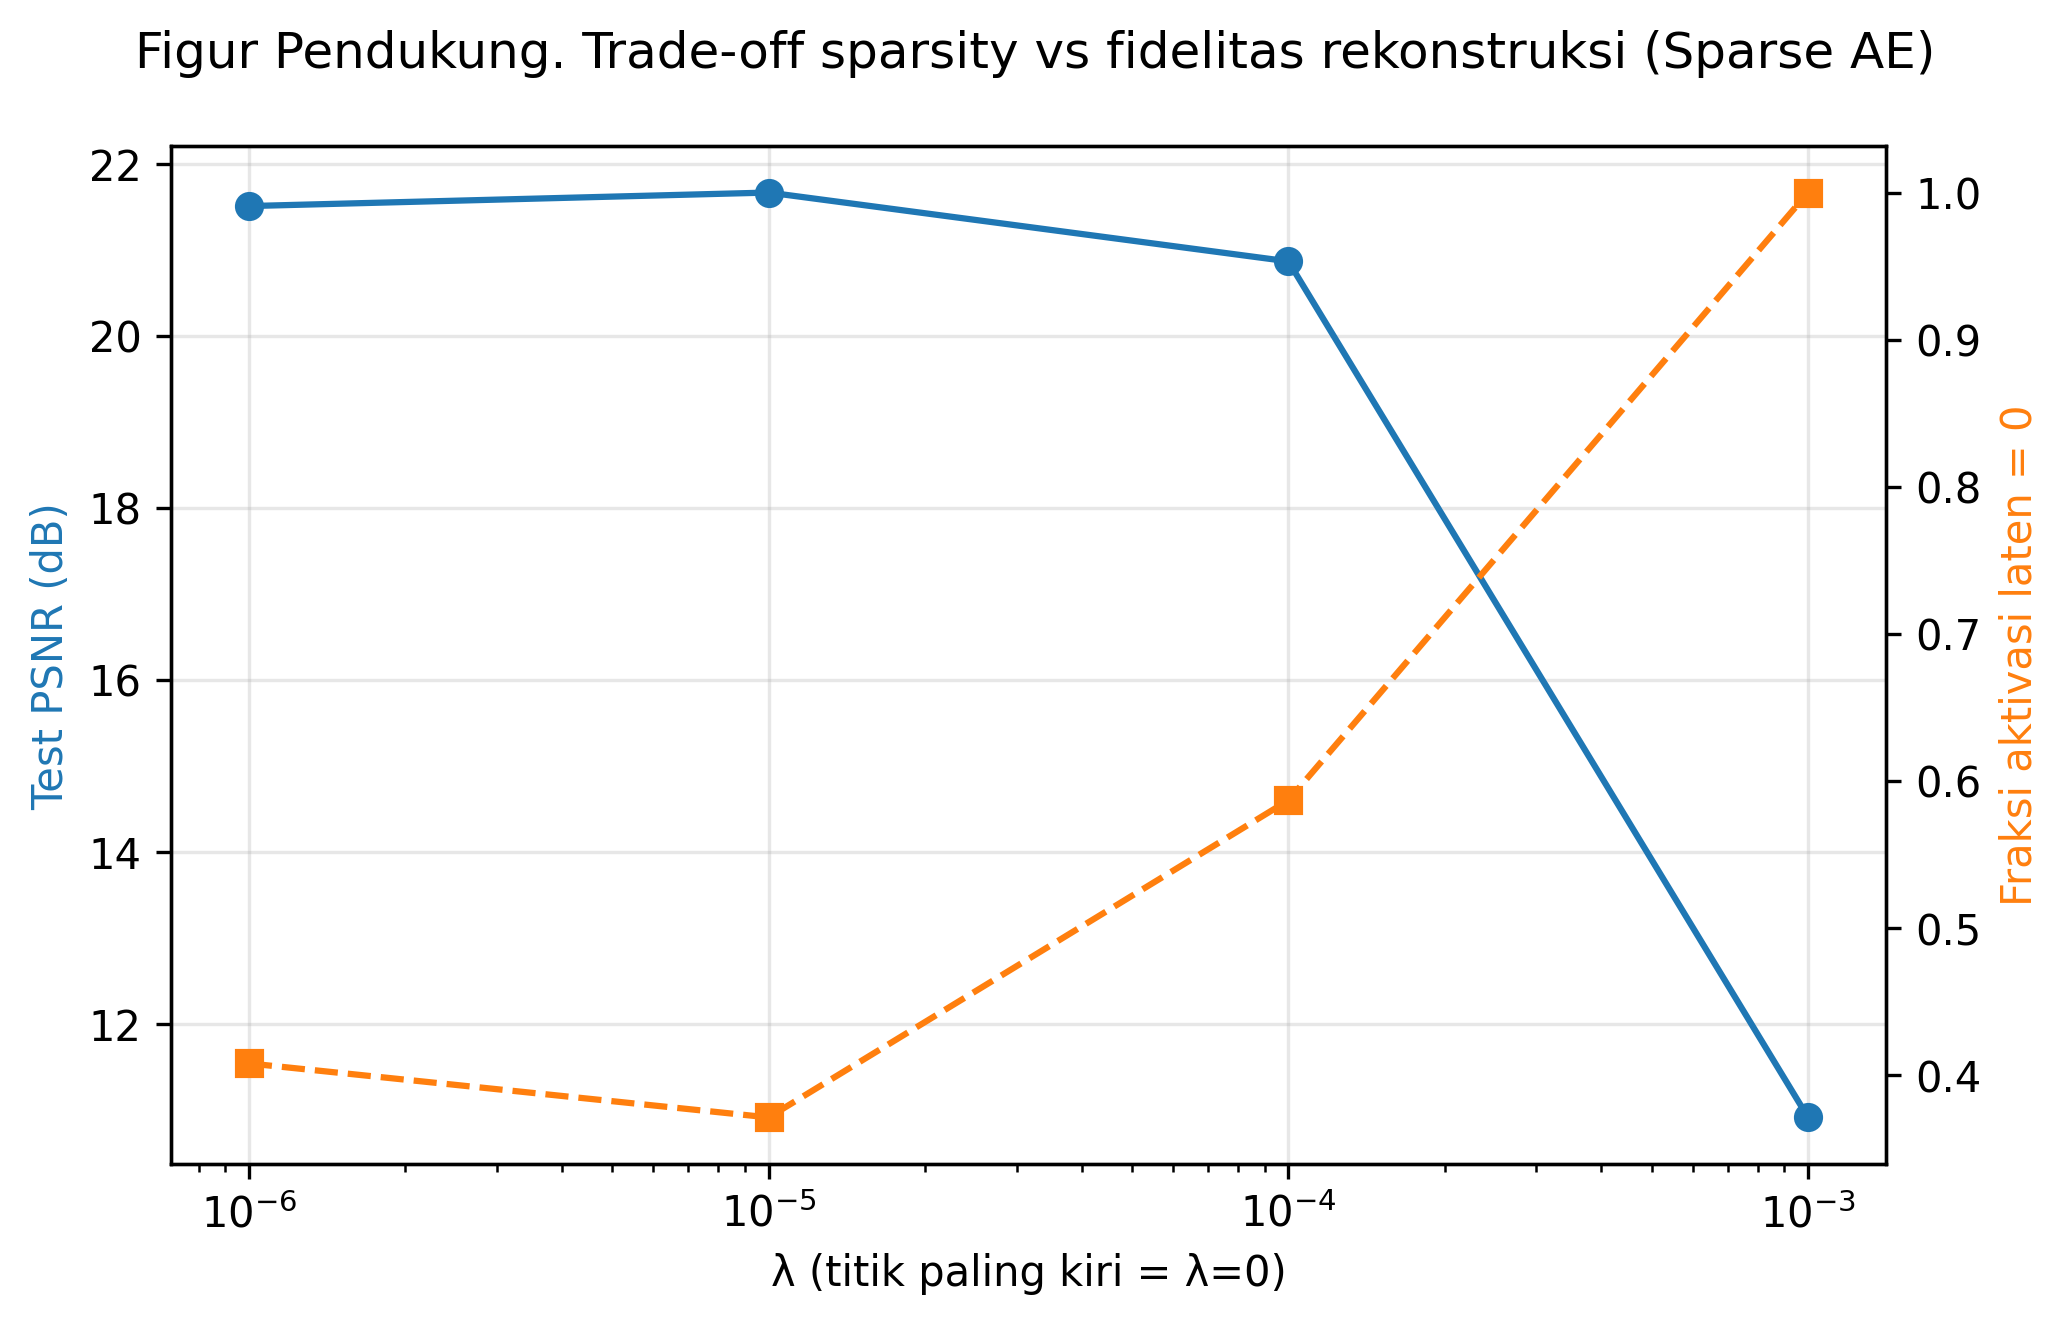

In [21]:
sweep_rows = []
for lam in cfg.sparse_sweep:
    log(f"=== Sweep Sparse AE λ={lam:g} ===")
    loaders["train"].generator.manual_seed(cfg.seed)
    m = train_autoencoder("sparse_ae", cfg, loaders, device, lam=lam, epochs=cfg.sweep_epochs)[0]["model"].eval()
    sweep_rows.append({"lambda": lam, **reconstruction_metrics(m.reconstruct, loaders["test"], device),
                       **latent_sparsity_stats(m.encode, loaders["test"], device)})
_write_table(sweep_rows, os.path.join(cfg.out_dir, "metrics", "sparse_lambda_sweep"))
figure_extra_sparse_sweep(sweep_rows, cfg)
show_fig("figS3_sparse_lambda_sweep.png", 600)

## 9. Figur
### Figur 1 — Rekonstruksi side-by-side

[15:34:29] Figur disimpan: /content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2/final_results/figures/fig1_reconstruction.png


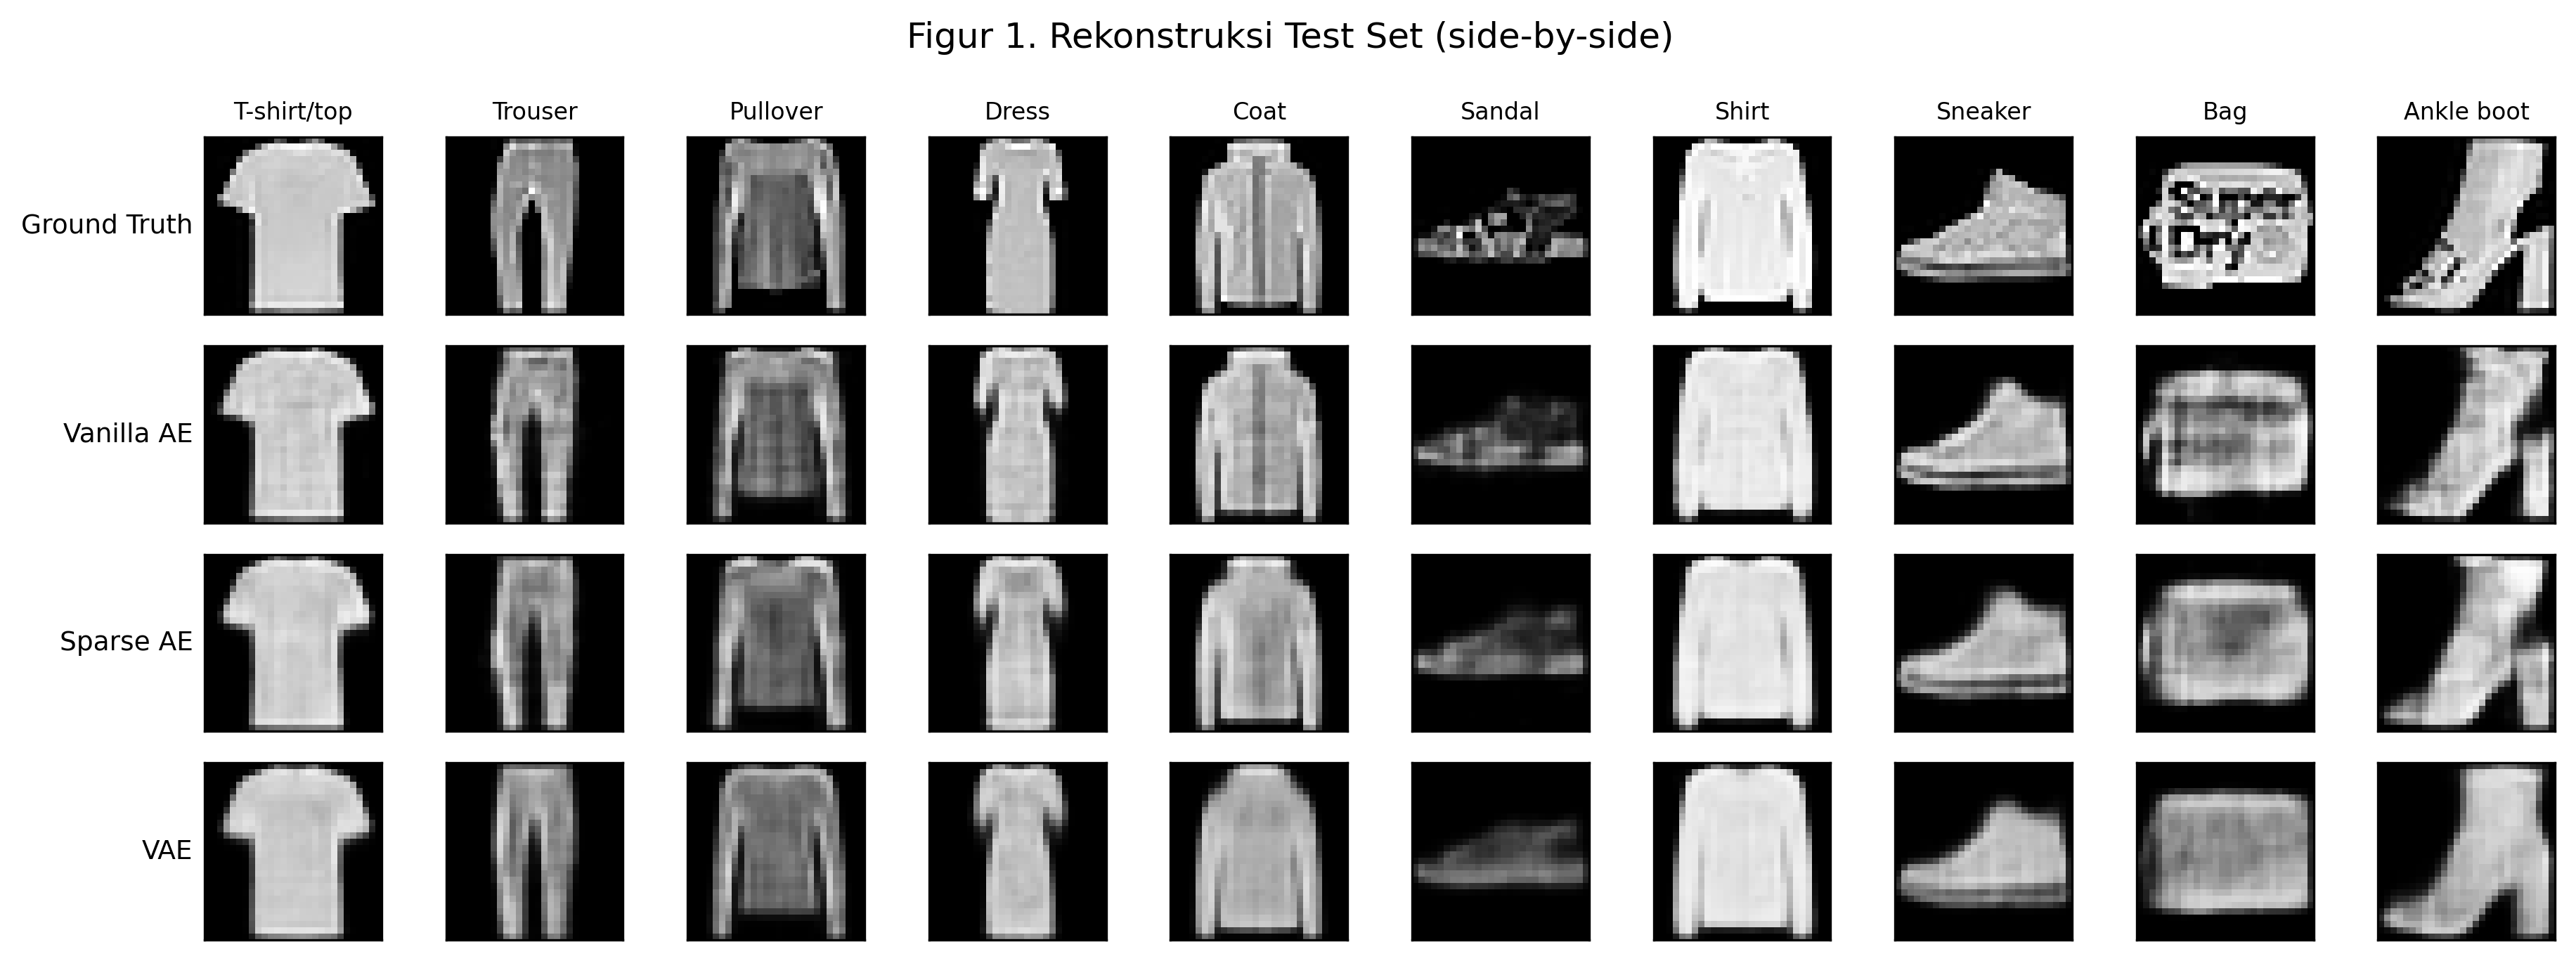

In [22]:
figure1_reconstruction(models, ds, cfg, device)
show_fig("fig1_reconstruction.png")

### Figur Pendukung S1 — Struktur fitur laten Vanilla AE vs Sparse AE (Q2)

[15:34:32] Figur disimpan: /content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2/final_results/figures/figS1_sparse_features.png


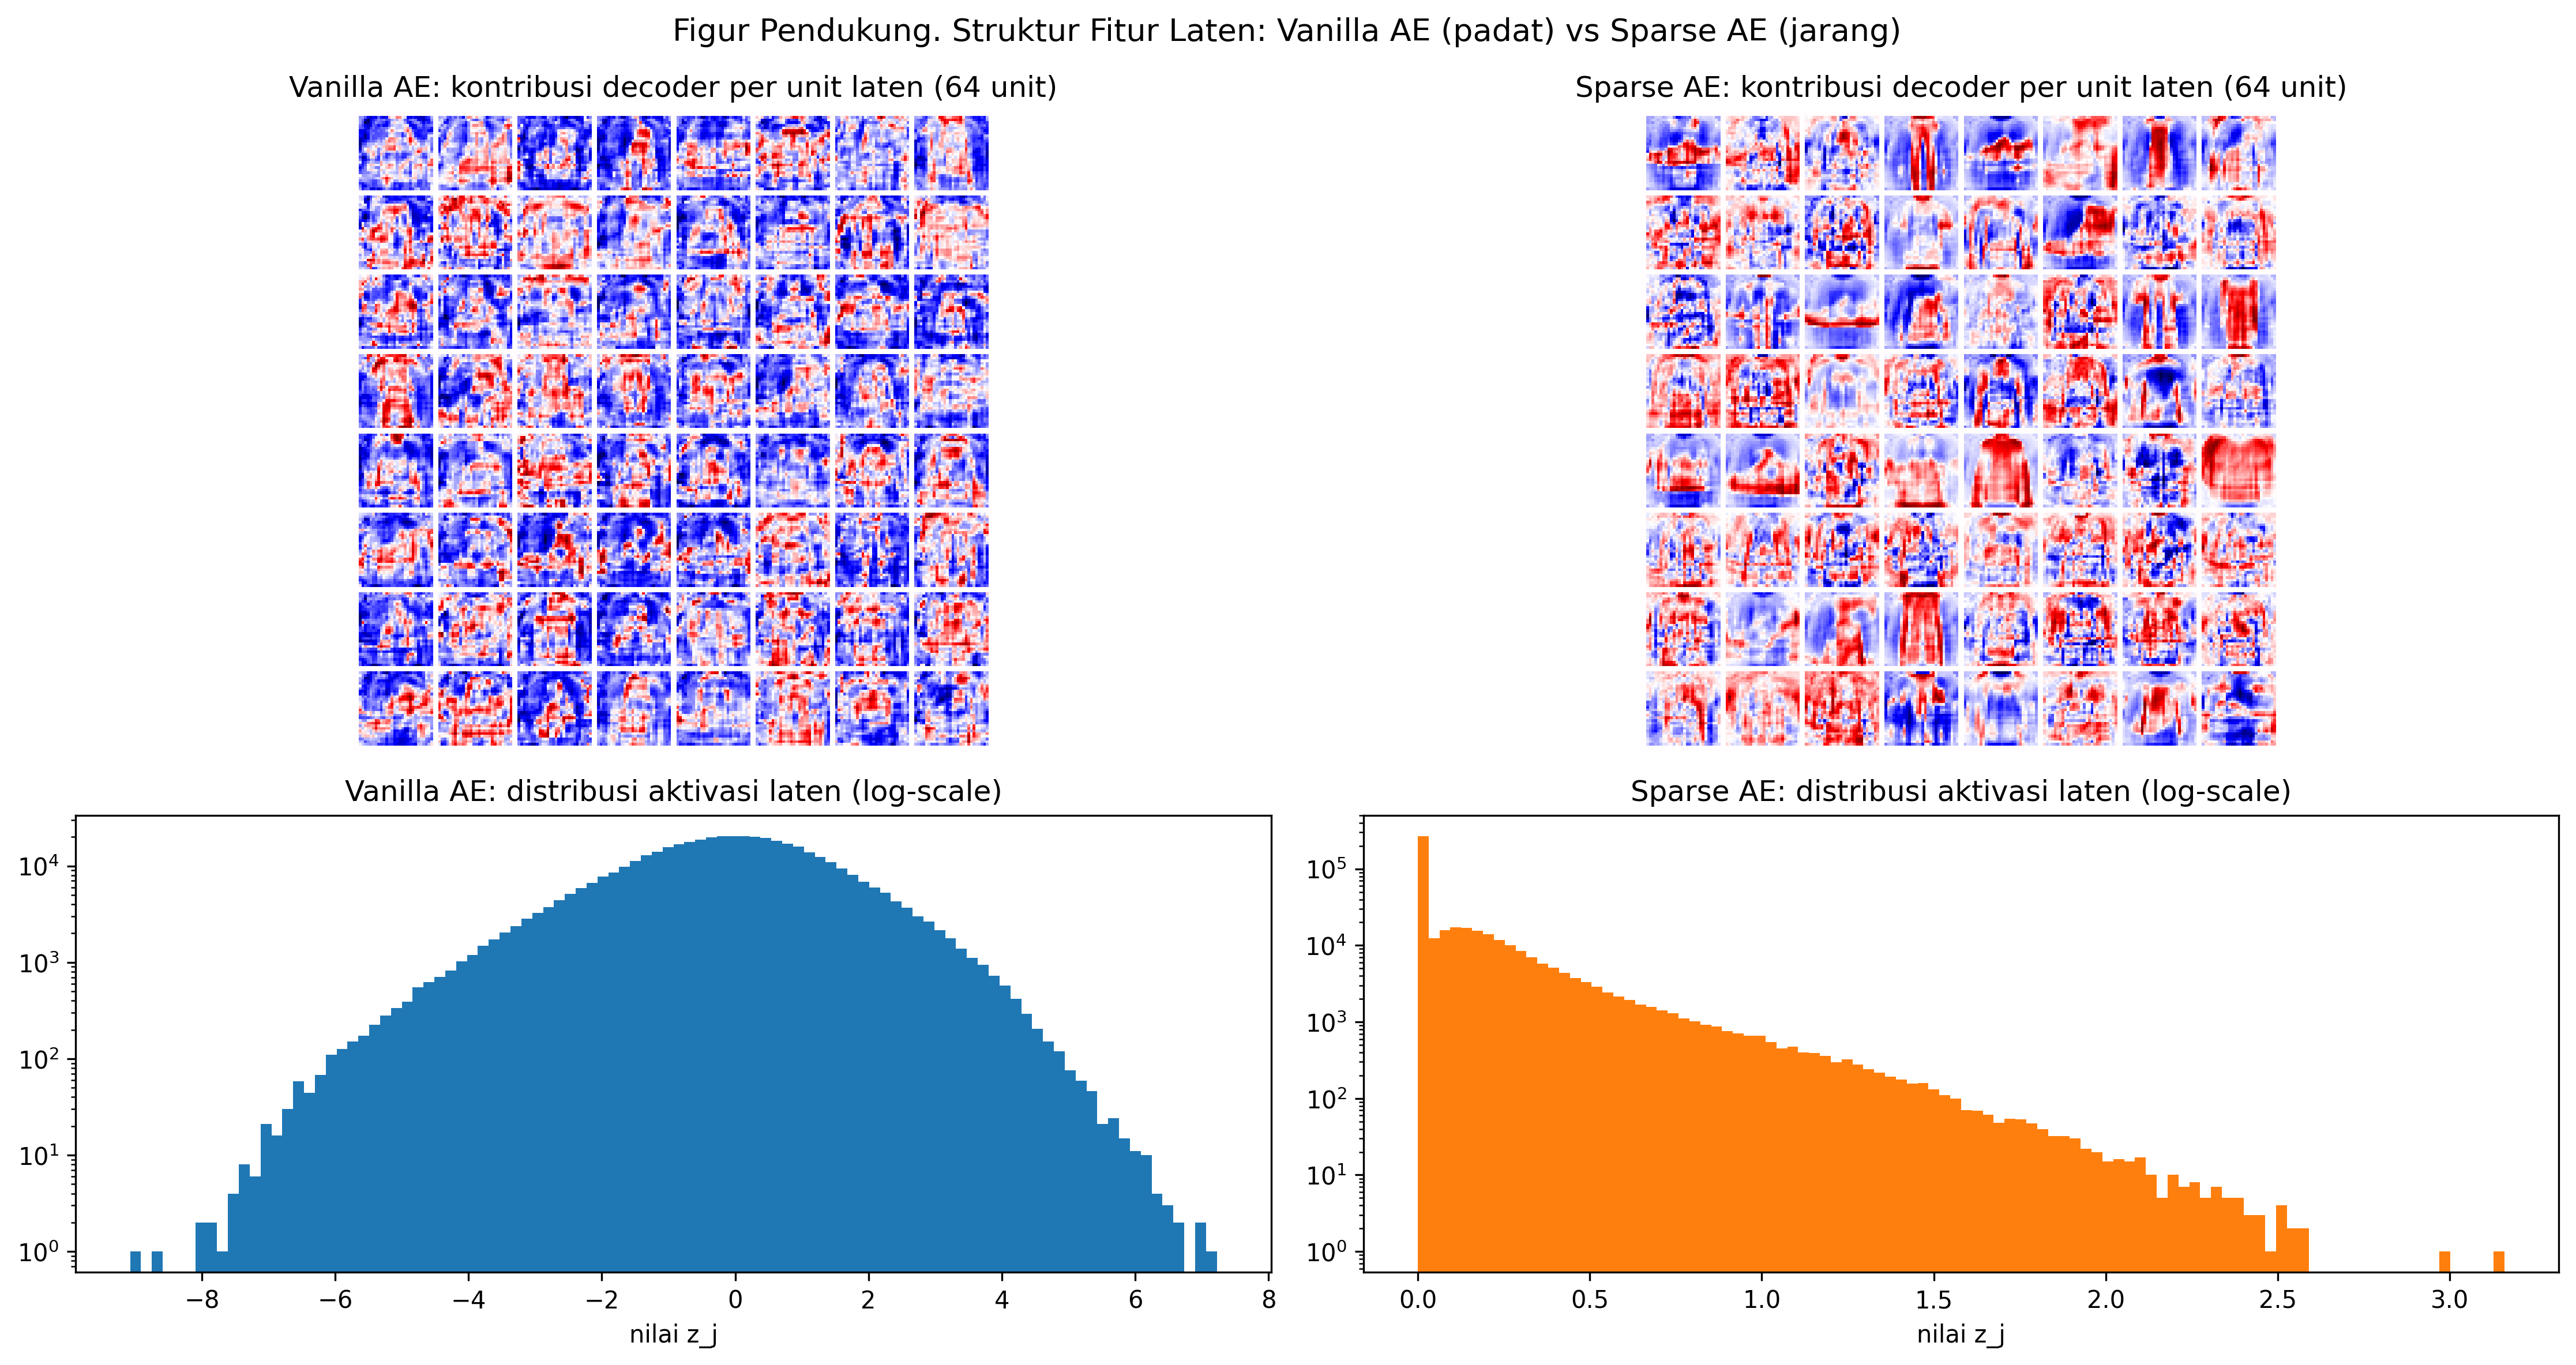

In [23]:
figure_extra_sparse_features(models, loaders, cfg, device)
show_fig("figS1_sparse_features.png")

### Interpolasi laten (bagian AE untuk Figur 4)
Disimpan ke Drive; Figur 4 lengkap (AE + GAN) dibuat di `05_summary.ipynb`.

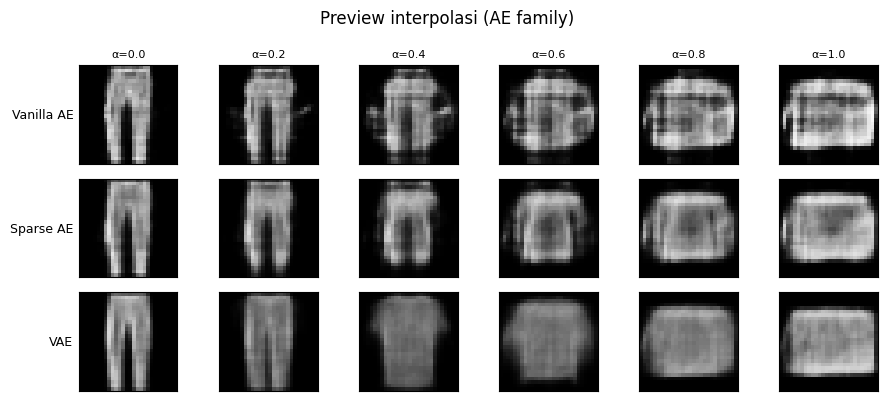

Vanilla AE   max/mean jump = 1.30 | nn_dist_ratio = [0.0, 0.62, 1.24, 1.24, 0.62, 0.0]
Sparse AE    max/mean jump = 1.56 | nn_dist_ratio = [0.0, 0.71, 1.41, 1.23, 0.71, 0.0]
VAE          max/mean jump = 1.30 | nn_dist_ratio = [0.0, 0.88, 1.1, 1.12, 0.88, 0.0]


In [24]:
interp_rows, interp_stats = run_interpolation(models, clf, ds, loaders, cfg, device)
torch.save(interp_rows, os.path.join(cfg.out_dir, "samples", "interp_rows_ae.pt"))
save_json(interp_stats, os.path.join(cfg.out_dir, "metrics", "interp_ae.json"))
fig = _image_rows([interp_rows[n] for n in interp_rows], [PRETTY[n] for n in interp_rows],
                  [f"α={a:.1f}" for a in cfg.interp_alphas], "Preview interpolasi (AE family)", (1.3, 1.35))
plt.show()
for n, d in interp_stats.items():
    print(f"{PRETTY[n]:12s} max/mean jump = {d['max_over_mean_jump']:.2f} | nn_dist_ratio =",
          [round(v, 2) for v in d["nn_dist_ratio"]])